In [2]:
import numpy as np
import pandas as pd

legs = pd.read_csv("flight_legs.csv", dtype=str)
airports = pd.read_csv("airports.csv")
turns = pd.read_csv("minimum_turn_times.csv")

# text columns: trim, upper-case codes, turn "empty" into a real null
for c in ["flight_number", "tail_number", "aircraft_type", "origin", "destination"]:
    legs[c] = legs[c].str.strip().str.upper()
legs["delay_reason_code"] = (legs["delay_reason_code"].str.strip().str.lower()
                             .replace({"empty": np.nan, "": np.nan}))

# types and timestamps (all UTC)
legs["leg_id"] = legs["leg_id"].astype(int)
ts_cols = ["scheduled_departure", "scheduled_arrival", "actual_departure", "actual_arrival"]
for c in ts_cols:
    legs[c] = pd.to_datetime(legs[c])

print("duplicate leg_ids:", legs["leg_id"].duplicated().sum())
legs = legs.drop_duplicates("leg_id")

# did the aircraft actually go?
legs["flew"] = legs["actual_departure"].notna() & legs["actual_arrival"].notna()
print(legs["flew"].value_counts())

duplicate leg_ids: 12
flew
True     11045
False      133
Name: count, dtype: int64


In [3]:
legs = legs.sort_values(["tail_number", "scheduled_departure", "leg_id"]).reset_index(drop=True)

g = legs.groupby("tail_number")
legs["prev_actual_arrival"] = g["actual_arrival"].shift(1)       # NaT if the previous leg never flew
legs["prev_scheduled_arrival"] = g["scheduled_arrival"].shift(1)
# no ffill on purpose: a stale arrival must not carry over a cancelled flight

In [4]:
legs = legs.merge(
    turns,
    left_on=["origin", "aircraft_type"],
    right_on=["airport_code", "aircraft_type"],
    how="left",
).drop(columns="airport_code")

print("legs with no minimum turn:", legs["minimum_turn_minutes"].isna().sum())  # should be 0

legs with no minimum turn: 0


In [5]:
def minutes(td):
    return td.dt.total_seconds() / 60

# look at the gaps first and pick the threshold where the distribution breaks
legs["sched_gap_min"] = minutes(legs["scheduled_departure"] - legs["prev_scheduled_arrival"])
print(legs["sched_gap_min"].describe())
print(pd.cut(legs["sched_gap_min"], [0, 60, 120, 180, 240, 360, 480, 720, 1e9]).value_counts().sort_index())

NEW_DAY_GAP = 360   # assumption: change it to match what you see above

earliest_departure = legs["prev_actual_arrival"] + pd.to_timedelta(legs["minimum_turn_minutes"], unit="m")
inherited = minutes(earliest_departure - legs["scheduled_departure"]).clip(lower=0)

fresh_start = legs["prev_scheduled_arrival"].isna() | (legs["sched_gap_min"] > NEW_DAY_GAP)
inherited = inherited.mask(fresh_start, 0)   # first leg overall / first leg of the day
inherited = inherited.fillna(0)              # previous leg never flew, so there is no arrival to inherit

count    11013.000000
mean       119.631526
std        164.767746
min       -349.000000
25%         59.000000
50%         76.000000
75%         94.000000
max       1454.000000
Name: sched_gap_min, dtype: float64
sched_gap_min
(0.0, 60.0]              2208
(60.0, 120.0]            5944
(120.0, 180.0]            176
(180.0, 240.0]            416
(240.0, 360.0]            723
(360.0, 480.0]            250
(480.0, 720.0]            406
(720.0, 1000000000.0]     159
Name: count, dtype: int64


In [6]:
dep_delay = minutes(legs["actual_departure"] - legs["scheduled_departure"])

# flights that never went stay empty
dep_delay = dep_delay.where(legs["flew"])
inherited = inherited.where(legs["flew"])
created = dep_delay - inherited             # keep the sign, no flooring

legs["departure_delay_minutes"] = dep_delay.round().astype("Int64")
legs["inherited_delay_minutes"] = inherited.round().astype("Int64")
legs["created_delay_minutes"] = created.round().astype("Int64")

flown = legs[legs["flew"]]
assert (flown["inherited_delay_minutes"] + flown["created_delay_minutes"]
        == flown["departure_delay_minutes"]).all()
print("negative created delays:", (flown["created_delay_minutes"] < 0).sum())

negative created delays: 6016


In [7]:
out = legs[["leg_id", "departure_delay_minutes", "inherited_delay_minutes",
            "created_delay_minutes"]].sort_values("leg_id")
out.to_csv("leg_delays.csv", index=False)

assert len(out) == legs["leg_id"].nunique()
print(out.isna().sum())    # nulls should equal the number of flights that never went

leg_id                       0
departure_delay_minutes    133
inherited_delay_minutes    133
created_delay_minutes      133
dtype: int64


In [8]:
T = 15
tail = legs["tail_number"].to_numpy()
inh = legs["inherited_delay_minutes"].to_numpy(dtype=float, na_value=np.nan)
cre = legs["created_delay_minutes"].to_numpy(dtype=float, na_value=np.nan)

is_root = (cre >= T) & (inh < T)        # NaN (never flew) compares as False

rows = []
for i in np.flatnonzero(is_root):
    j, n, total = i + 1, 0, 0
    while j < len(legs) and tail[j] == tail[i] and inh[j] >= T:   # stops at a cancelled flight too
        n += 1
        total += inh[j]
        j += 1
    rows.append((i, n, int(total)))

idx = [r[0] for r in rows]
roots = legs.loc[idx, ["leg_id", "flight_number", "tail_number", "origin",
                       "scheduled_departure", "created_delay_minutes"]].copy()
roots["downstream_legs_affected"] = [r[1] for r in rows]
roots["downstream_delay_minutes"] = [r[2] for r in rows]

roots = roots.sort_values(
    ["downstream_delay_minutes", "downstream_legs_affected", "created_delay_minutes"],
    ascending=False,
).reset_index(drop=True)
roots.to_csv("cascade_roots.csv", index=False)
roots.head(10)

,leg_id,flight_number,tail_number,origin,scheduled_departure,created_delay_minutes,downstream_legs_affected,downstream_delay_minutes
0,3104051,AA1650,N360AA,PHX,2025-11-05 06:00:00,230,7,1204
1,3105619,AA1418,N383AA,ORD,2025-11-08 05:16:00,255,6,1115
2,3104733,AA2332,N370AA,BNA,2025-11-08 17:48:00,275,3,965
3,3108961,AA2960,N432AA,ORD,2025-11-08 10:52:00,274,4,944
4,3108663,AA2662,N428AA,CLT,2025-11-06 01:14:00,128,3,837
5,3111000,AA1399,N462AA,CLT,2025-11-09 20:34:00,170,5,760
6,3111028,AA1427,N462AA,LAX,2025-11-15 05:37:00,196,5,742
7,3102939,AA2338,N344AA,DFW,2025-11-05 09:09:00,150,5,682
8,3106004,AA1803,N389AA,SJC,2025-11-06 05:19:00,30,6,650
9,3105224,AA2823,N377AA,TUS,2025-11-13 11:38:00,165,5,647


In [9]:
legs = legs.merge(airports[["airport_code", "timezone", "is_hub"]],
                  left_on="origin", right_on="airport_code", how="left")

# local hour: convert per time zone, using the origin airport's clock
legs["local_hour"] = np.nan
for tz, grp in legs.groupby("timezone"):
    local = grp["scheduled_departure"].dt.tz_localize("UTC").dt.tz_convert(tz)
    legs.loc[grp.index, "local_hour"] = local.dt.hour

flown = legs[legs["flew"]].copy()
flown["is_root"] = (flown["created_delay_minutes"] >= T) & (flown["inherited_delay_minutes"] < T)

by_airport = (flown.groupby("origin")
              .agg(departures=("leg_id", "size"), delay_starts=("is_root", "sum")))
by_airport["start_rate_pct"] = 100 * by_airport["delay_starts"] / by_airport["departures"]
print(by_airport.sort_values("delay_starts", ascending=False).head(10))
print(by_airport.sort_values("start_rate_pct", ascending=False).head(10))

by_hour = (flown.groupby("local_hour")
           .agg(departures=("leg_id", "size"), delay_starts=("is_root", "sum")))
by_hour["start_rate_pct"] = 100 * by_hour["delay_starts"] / by_hour["departures"]
print(by_hour)

        departures  delay_starts  start_rate_pct
origin                                          
DFW            801           130       16.229713
CLT            757           107       14.134742
PHX            735           105       14.285714
LAX            785           103       13.121019
MIA            769           103       13.394018
ORD            746            99       13.270777
DCA            794            94       11.838791
PHL            800            86           10.75
MCI            319            48       15.047022
CMH            284            47       16.549296
        departures  delay_starts  start_rate_pct
origin                                          
CMH            284            47       16.549296
DFW            801           130       16.229713
MSY            285            46       16.140351
MCI            319            48       15.047022
AUS            288            43       14.930556
SAT            303            45       14.851485
JAX            304  

In [10]:
delayed = flown[flown["departure_delay_minutes"] >= T].copy()

delayed["recorded"] = np.where(
    delayed["delay_reason_code"].isna(), "no reason",
    np.where(delayed["delay_reason_code"] == "late_inbound_aircraft", "late_inbound", "airport reason"))
delayed["arithmetic"] = np.where(delayed["inherited_delay_minutes"] >= T, "inherited>=15", "inherited<15")

print(pd.crosstab(delayed["recorded"], delayed["arithmetic"], margins=True))

scored = delayed[delayed["recorded"] != "no reason"]
agree = (((scored["recorded"] == "late_inbound") & (scored["inherited_delay_minutes"] >= T)) |
         ((scored["recorded"] == "airport reason") & (scored["inherited_delay_minutes"] < T)))
print("agreement:", round(agree.mean() * 100, 1), "%  | no reason recorded:",
      round((delayed["recorded"] == "no reason").mean() * 100, 1), "%")

arithmetic      inherited<15  inherited>=15   All
recorded                                         
airport reason          1269            136  1405
late_inbound               6            530   536
no reason                232            132   364
All                     1507            798  2305
agreement: 92.7 %  | no reason recorded: 15.8 %


In [11]:
checks = {
    "one row per leg": len(out) == len(pd.read_csv("flight_legs.csv")),
    "cancelled flights are empty, not 0": out["departure_delay_minutes"].isna().sum() == (~legs["flew"]).sum(),
    "inherited never negative": (flown["inherited_delay_minutes"] >= 0).all(),
    "some negative created values": (flown["created_delay_minutes"] < 0).any(),
    "first leg per tail inherits 0": (legs.groupby("tail_number").head(1)["inherited_delay_minutes"].fillna(0) == 0).all(),
}
print(pd.Series(checks))
print(roots.head(10))   # large created delay and a long downstream run?

one row per leg                       False
cancelled flights are empty, not 0     True
inherited never negative               True
some negative created values           True
first leg per tail inherits 0          True
dtype: bool
    leg_id flight_number tail_number origin scheduled_departure  \
0  3104051        AA1650      N360AA    PHX 2025-11-05 06:00:00   
1  3105619        AA1418      N383AA    ORD 2025-11-08 05:16:00   
2  3104733        AA2332      N370AA    BNA 2025-11-08 17:48:00   
3  3108961        AA2960      N432AA    ORD 2025-11-08 10:52:00   
4  3108663        AA2662      N428AA    CLT 2025-11-06 01:14:00   
5  3111000        AA1399      N462AA    CLT 2025-11-09 20:34:00   
6  3111028        AA1427      N462AA    LAX 2025-11-15 05:37:00   
7  3102939        AA2338      N344AA    DFW 2025-11-05 09:09:00   
8  3106004        AA1803      N389AA    SJC 2025-11-06 05:19:00   
9  3105224        AA2823      N377AA    TUS 2025-11-13 11:38:00   

   created_delay_minutes  down

In [12]:
from google.colab import files
files.download("leg_delays.csv")
files.download("cascade_roots.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FileNotFoundError: Cannot find file: figures/delay_starts_by_airport.png

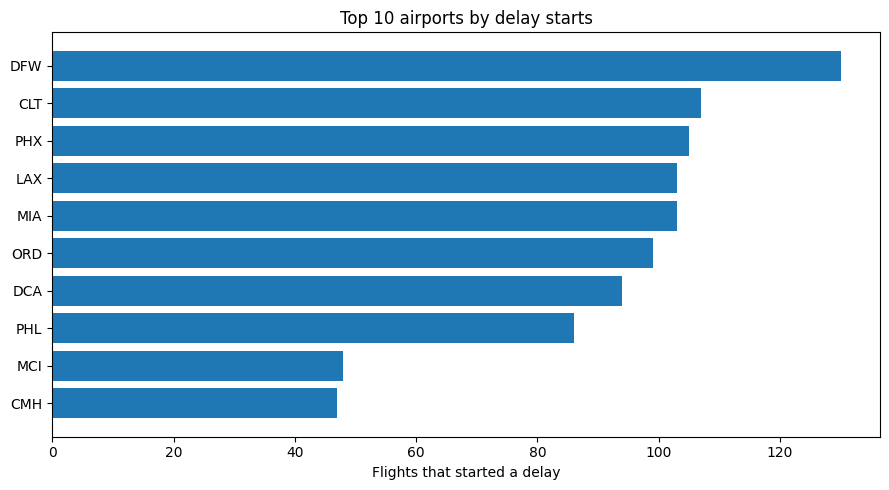

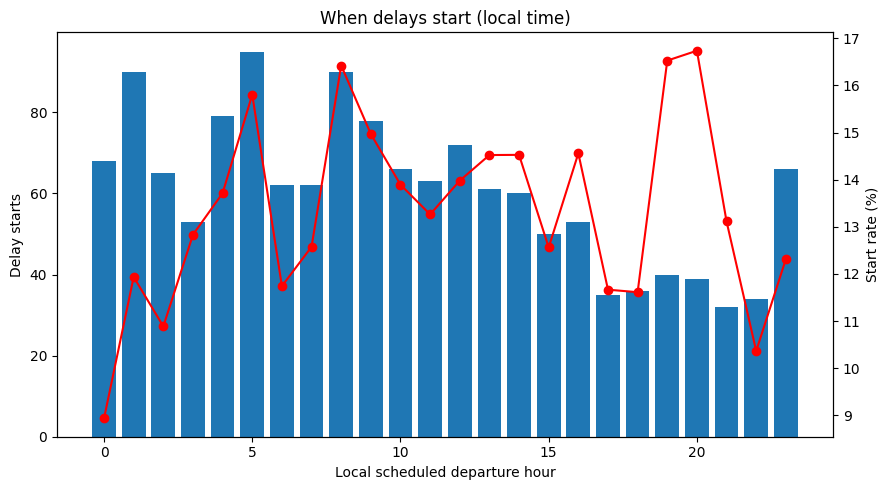

In [13]:
import matplotlib.pyplot as plt
import os
os.makedirs("figures", exist_ok=True)

top = by_airport.sort_values("delay_starts", ascending=False).head(10)[::-1]
plt.figure(figsize=(9, 5))
plt.barh(top.index, top["delay_starts"])
plt.xlabel("Flights that started a delay")
plt.title("Top 10 airports by delay starts")
plt.tight_layout()
plt.savefig("figures/delay_starts_by_airport.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(by_hour.index, by_hour["delay_starts"])
ax.set_xlabel("Local scheduled departure hour")
ax.set_ylabel("Delay starts")
ax2 = ax.twinx()
ax2.plot(by_hour.index, by_hour["start_rate_pct"], marker="o", color="red")
ax2.set_ylabel("Start rate (%)")
plt.title("When delays start (local time)")
plt.tight_layout()
plt.savefig("figures/delay_starts_by_local_hour.png", dpi=150)
plt.show()

In [14]:
files.download("figures/delay_starts_by_airport.png")
files.download("figures/delay_starts_by_local_hour.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>